In [1]:
!nvidia-smi

Tue Nov  3 15:53:11 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 591.80                 Driver Version: 591.80         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 2050      WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   46C    P3            310W /   30W |       0MiB /   4096MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
#%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [1]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
import cv2
import os

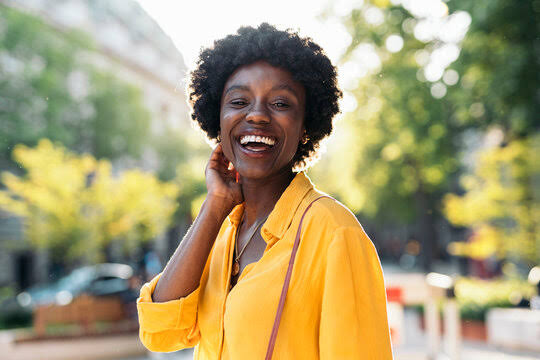

In [2]:
img=image.load_img(r"C:\Users\vamsikrishna\OneDrive\Documents\projects\mood_pro\train\happy\images (7).jpeg")
img

In [4]:
i1=cv2.imread(r"C:\Users\vamsikrishna\OneDrive\Documents\projects\mood_pro\train\happy\images (7).jpeg")
i1

array([[[157, 155, 161],
        [158, 157, 161],
        [162, 161, 163],
        ...,
        [ 39,  57,  40],
        [ 38,  56,  39],
        [ 37,  55,  38]],

       [[151, 156, 155],
        [153, 158, 157],
        [157, 162, 161],
        ...,
        [ 44,  62,  45],
        [ 43,  61,  44],
        [ 43,  61,  44]],

       [[140, 155, 147],
        [143, 158, 150],
        [150, 162, 156],
        ...,
        [ 42,  60,  43],
        [ 42,  60,  43],
        [ 42,  60,  43]],

       ...,

       [[184, 191, 210],
        [184, 191, 210],
        [185, 192, 211],
        ...,
        [185, 181, 187],
        [186, 182, 188],
        [186, 182, 188]],

       [[183, 190, 209],
        [183, 190, 209],
        [183, 190, 209],
        ...,
        [197, 197, 203],
        [196, 196, 202],
        [194, 194, 200]],

       [[182, 189, 208],
        [182, 189, 208],
        [183, 190, 209],
        ...,
        [214, 217, 222],
        [212, 215, 220],
        [209, 212, 217]]

In [5]:
i1.shape

(360, 540, 3)

In [6]:
train=ImageDataGenerator(rescale=1/255)
validation=ImageDataGenerator(rescale=1/255)

In [7]:
train_dataset = train.flow_from_directory(r"C:\Users\vamsikrishna\OneDrive\Documents\projects\mood_pro\train",
                                         target_size = (200,200),
                                         batch_size = 3,
                                         class_mode = 'binary')
validation_dataset = validation.flow_from_directory(r"C:\Users\vamsikrishna\OneDrive\Documents\projects\mood_pro\validation",
                                          target_size = (200,200),
                                          batch_size = 3,
                                          class_mode = 'binary')

Found 28 images belonging to 2 classes.
Found 0 images belonging to 2 classes.


In [8]:
 train_dataset.class_indices

{'happy': 0, 'sad': 1}

In [9]:
validation_dataset.class_indices

{'happy': 0, 'sad': 1}

In [10]:
 train_dataset.classes

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1], dtype=int32)

In [19]:
model = tf.keras.models.Sequential([ tf.keras.layers.Conv2D(16,(3,3),activation = 'relu',
                                                            input_shape = (200,200,3)),
                                    tf.keras.layers.MaxPool2D(2,2), #3 filtr we applied hear
                                    #
                                    tf.keras.layers.Conv2D(32,(3,3),activation = 'relu'),
                                    tf.keras.layers.MaxPool2D(2,2),
                                    #
                                    tf.keras.layers.Conv2D(64,(3,3),activation = 'relu'),
                                    tf.keras.layers.MaxPool2D(2,2),
                                    ##
                                    tf.keras.layers.Flatten(),
                                    ##
                                    tf.keras.layers.Dense(512, activation = 'relu'),
                                    #
                                    tf.keras.layers.Dense(1,activation= 'sigmoid')
                                    ]
                                    )
model.summary()

c:\Users\vamsikrishna\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 198, 198, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 99, 99, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 97, 97, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 46, 46, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 33856)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    17,334,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,358,881 (66.22 MB)

 Trainable params: 17,358,881 (66.22 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.compile(loss='binary_crossentropy',
              optimizer=tf.keras.optimizers.RMSprop(learning_rate=0.001),
              metrics=['accuracy']
              )

In [11]:
model_fit=model.fit(train_dataset,
                   steps_per_epoch=3,
                   epochs=25,
                  validation_data=validation_dataset)
                   # Temporarily removed validation_data=validation_dataset because it contains 0 images

NameError: name 'model' is not defined